<font size=7 color="#5499C7" >Final Project</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

In [1]:
import os
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

import kagglehub

In [2]:
# Reproducibility
SEED = 42
DETERMINISTIC = True

# Runtime controls
FAST_RUN = False  # True: smaller subset + lower resolution for quick smoke tests
EPOCHS = 67 # Smaller epochs for faster runs
MIXED_PRECISION = False

# Dataset selection
DATASET_SLUG = "vikramtiwari/pix2pix-dataset"
DATASET_NAME = "edges2shoes"
DIRECTION = "AtoB"

# Image sizes and batching
FULL_IMG_SIZE = 256
FAST_IMG_SIZE = 256
IMG_SIZE = FAST_IMG_SIZE if FAST_RUN else FULL_IMG_SIZE

FULL_BATCH_SIZE = 16
FAST_BATCH_SIZE = 4
BATCH_SIZE = FAST_BATCH_SIZE if FAST_RUN else FULL_BATCH_SIZE

# Data loading limits (None = full split)
FAST_TRAIN_LIMIT = 200
FAST_VAL_LIMIT = 80
FAST_TEST_LIMIT = 80
MAX_TRAIN_SAMPLES = FAST_TRAIN_LIMIT if FAST_RUN else None
MAX_VAL_SAMPLES = FAST_VAL_LIMIT if FAST_RUN else None
MAX_TEST_SAMPLES = FAST_TEST_LIMIT if FAST_RUN else None

# Training hyperparameters
LR = 2e-4
BETA1 = 0.5
BETA2 = 0.999
LAMBDA_L1 = 100.0

# Training loop controls
MAX_STEPS_PER_EPOCH = 50 if FAST_RUN else None
LOG_EVERY_N_STEPS = 20


# Early stopping
USE_EARLY_STOPPING = True
EARLY_STOP_METRIC = "l1"  # options: "l1", "psnr", "ssim"
EARLY_STOP_MODE = "min"   # "min" for L1, "max" for PSNR/SSIM
EARLY_STOP_PATIENCE = 5
EARLY_STOP_MIN_DELTA = 1e-4

# Optional corruption settings (for restoration tasks)
CORRUPT_INPUT = False
CORRUPTION_MAX_FRAC = 0.4
CORRUPTION_NOISE_STD = 0.0

# Evaluation settings
EVAL_MAX_BATCHES = 10 if FAST_RUN else None
BASELINE_EVAL_MAX_BATCHES = 5 if FAST_RUN else None

# Checkpointing and outputs
CHECKPOINT_DIR = "/kaggle/working"
SAMPLE_DIR = "/kaggle/working/samples"
SAVE_SAMPLE_EVERY_N_STEPS = 100
SAVE_CHECKPOINT_EVERY_EPOCH = True
LOAD_CHECKPOINT = False

# DataLoader performance
NUM_WORKERS = 0 if FAST_RUN else 2
PIN_MEMORY = True

# Device
DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"

<font size=7 color="#5499C7">Pix2Pix Image Translation</font>

This notebook implements a from-scratch pix2pix pipeline for paired image-to-image translation on edges2shoes.


<font size=6 color="#5499C7">Goal</font>
<font size=5>

Train a U-Net generator and PatchGAN discriminator from scratch, evaluate with PSNR/SSIM, and provide an interactive demo.

</font>


<font size=7 color="#5499C7">Assumptions</font>

A few reasonable assumptions are documented to keep the notebook self-contained and runnable.


<font size=6 color="#5499C7">Notes</font>
<font size=5>

The task is treated as paired translation (edges -> shoes). Synthetic corruption is disabled by default (CORRUPT_INPUT=False) but can be enabled if a restoration setup is required. Metrics are computed on images scaled to [0, 1].

</font>


In [3]:
def set_seed(seed, deterministic=True):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED, DETERMINISTIC)
DEVICE = torch.device(DEVICE_STR)
print("Device:", DEVICE)
print("FAST_RUN:", FAST_RUN)

os.makedirs(SAMPLE_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

Device: cuda
FAST_RUN: True


<font size=7 color="#5499C7">Dataset</font>

We use the Kaggle pix2pix dataset and select the edges2shoes subset.


<font size=6 color="#5499C7">Loading</font>
<font size=5>

The dataset is downloaded with kagglehub and a fallback search checks typical Kaggle input locations.

</font>


In [ ]:
candidates = [
    Path("/kaggle/input/pix2pix-dataset/edges2shoes/edges2shoes"),
    Path("/kaggle/input/pix2pix-dataset/edges2shoes"),
    Path("/kaggle/input/pix2pix-dataset"),
]

dataset_root = None
for c in candidates:
    if (c / "train").exists() and (c / "val").exists():
        dataset_root = c
        break

if dataset_root is None:
    # fallback: download
    path = kagglehub.dataset_download(DATASET_SLUG)
    dataset_root = Path(path)
    # if kagglehub returns a parent, search one level
    if not (dataset_root / "train").exists():
        for child in dataset_root.glob("**/train"):
            dataset_root = child.parent
            break

if dataset_root is None or not (dataset_root / "train").exists():
    raise FileNotFoundError("Could not find a folder with train/val splits.")

print("Using dataset root:", dataset_root)
print("Train files:", len(list((dataset_root / "train").glob("*"))))
print("Val files:", len(list((dataset_root / "val").glob("*"))))

Using dataset root: /kaggle/input/pix2pix-dataset/edges2shoes/edges2shoes
Train files: 49825
Val files: 200


In [5]:
def apply_corruption(img, max_frac=CORRUPTION_MAX_FRAC, noise_std=CORRUPTION_NOISE_STD):
    if max_frac <= 0 and noise_std <= 0:
        return img, Image.new("L", img.size, 0)

    np_img = np.array(img).astype(np.float32)
    h, w = np_img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    if max_frac > 0:
        cut_w = max(1, int(w * random.uniform(0.1, max_frac)))
        cut_h = max(1, int(h * random.uniform(0.1, max_frac)))
        x0 = random.randint(0, max(0, w - cut_w))
        y0 = random.randint(0, max(0, h - cut_h))
        np_img[y0:y0 + cut_h, x0:x0 + cut_w] = 0
        mask[y0:y0 + cut_h, x0:x0 + cut_w] = 1

    if noise_std > 0:
        noise = np.random.normal(0, noise_std, np_img.shape).astype(np.float32)
        np_img = np.clip(np_img + noise, 0, 255)
        mask[:, :] = 1

    corrupted = Image.fromarray(np_img.astype(np.uint8))
    mask_img = Image.fromarray((mask * 255).astype(np.uint8))
    return corrupted, mask_img

class Pix2PixDataset(Dataset):
    def __init__(self, root, split, img_size, max_samples=None, augment=False, apply_corruption=False, direction="AtoB"):
        self.root = Path(root)
        self.split = split
        self.files = sorted((self.root / split).glob("*"))
        if max_samples is not None:
            self.files = self.files[:max_samples]
        self.augment = augment
        self.apply_corruption = apply_corruption
        self.direction = direction

        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=Image.BICUBIC),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.mask_transform = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=Image.NEAREST),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert("RGB")
        w, h = img.size
        w2 = w // 2
        img_A = img.crop((0, 0, w2, h))
        img_B = img.crop((w2, 0, w, h))

        if self.direction == "BtoA":
            img_A, img_B = img_B, img_A

        if self.augment and random.random() < 0.5:
            img_A = img_A.transpose(Image.FLIP_LEFT_RIGHT)
            img_B = img_B.transpose(Image.FLIP_LEFT_RIGHT)

        mask = Image.new("L", img_A.size, 0)
        if self.apply_corruption:
            img_A, mask = apply_corruption(img_A)

        img_A = self.transform(img_A)
        img_B = self.transform(img_B)
        mask = self.mask_transform(mask)
        return img_A, img_B, mask

test_split = "test" if (dataset_root / "test").exists() else "val"
if test_split == "val":
  print("No test split found; using val as test.")

train_ds = Pix2PixDataset(
    dataset_root,
    split="train",
    img_size=IMG_SIZE,
    max_samples=MAX_TRAIN_SAMPLES,
    augment=True,
    apply_corruption=CORRUPT_INPUT,
    direction=DIRECTION,
)
val_ds = Pix2PixDataset(
    dataset_root,
    split="val",
    img_size=IMG_SIZE,
    max_samples=MAX_VAL_SAMPLES,
    augment=False,
    apply_corruption=CORRUPT_INPUT,
    direction=DIRECTION,
)
test_ds = Pix2PixDataset(
    dataset_root,
    split=test_split,
    img_size=IMG_SIZE,
    max_samples=MAX_TEST_SAMPLES,
    augment=False,
    apply_corruption=CORRUPT_INPUT,
    direction=DIRECTION,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print(f"Train/Val/Test sizes: {len(train_ds)}/{len(val_ds)}/{len(test_ds)}")

No test split found; using val as test.
Train/Val/Test sizes: 200/80/80


<font size=7 color="#5499C7">Direction Sanity Check</font>

Run this once before training to verify the input/target order.


<font size=6 color="#5499C7">Check</font>
<font size=5>

If the input does not look like edges and the ground truth does not look like shoes, set DIRECTION = "BtoA" and rerun.

</font>

In [ ]:
@torch.no_grad()
def show_direction_sanity_check(split="val", index=0):
    ds_map = {"train": train_ds, "val": val_ds, "test": test_ds}
    ds = ds_map[split]
    if len(ds) == 0:
        print(f"No samples available in {split} split.")
        return

    index = min(index, len(ds) - 1)
    real_A, real_B, _ = ds[index]

    def to_img(t):
        t = (t * 0.5 + 0.5).clamp(0, 1)
        return np.transpose(t.numpy(), (1, 2, 0))

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    for ax in axes:
        ax.axis("off")

    axes[0].imshow(to_img(real_A))
    axes[0].set_title("Input (A)")
    axes[1].imshow(to_img(real_B))
    axes[1].set_title("Ground Truth (B)")
    plt.show()

    print("If the input is not edges and the ground truth is not shoes, set DIRECTION = \"BtoA\" and rerun.")

show_direction_sanity_check(split="val", index=0)

<font size=7 color="#5499C7">Model</font>

The generator is a U-Net and the discriminator is a 70x70 PatchGAN, implemented from scratch.


<font size=6 color="#5499C7">Architecture</font>
<font size=5>

We follow the original pix2pix design: a U-Net encoder-decoder with skip connections and a convolutional PatchGAN discriminator that conditions on input-target pairs.

</font>


In [6]:
class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)
        ]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.model(x)
        return torch.cat([x, skip], dim=1)

class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512)
        self.down5 = UNetDown(512, 512)
        self.down6 = UNetDown(512, 512)
        self.down7 = UNetDown(512, 512)
        self.down8 = UNetDown(512, 512, normalize=False)

        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 512, dropout=0.5)
        self.up4 = UNetUp(1024, 512)
        self.up5 = UNetUp(1024, 256)
        self.up6 = UNetUp(512, 128)
        self.up7 = UNetUp(256, 64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)
        return self.final(u7)

class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        def disc_block(in_filters, out_filters, normalize=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, 2, 1, bias=False)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *disc_block(in_channels * 2, 64, normalize=False),
            *disc_block(64, 128),
            *disc_block(128, 256),
            *disc_block(256, 512),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1),
        )

    def forward(self, img_A, img_B):
        x = torch.cat([img_A, img_B], dim=1)
        return self.model(x)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)


generator = UNetGenerator().to(DEVICE)
discriminator = PatchDiscriminator().to(DEVICE)

generator.apply(init_weights)
discriminator.apply(init_weights)

print("Generator params:", sum(p.numel() for p in generator.parameters()) / 1e6, "M")
print("Discriminator params:", sum(p.numel() for p in discriminator.parameters()) / 1e6, "M")

Generator params: 54.413955 M
Discriminator params: 2.768641 M


<font size=7 color="#5499C7">Training</font>

We use adversarial loss (GAN) plus L1 reconstruction loss, as in the original pix2pix formulation.


<font size=6 color="#5499C7">Losses</font>
<font size=5>

The discriminator is trained with BCEWithLogitsLoss on real vs. fake pairs, and the generator optimizes GAN loss + L1 with weight LAMBDA_L1.

</font>


In [ ]:
criterion_gan = nn.BCEWithLogitsLoss()
criterion_l1 = nn.L1Loss()

optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR, betas=(BETA1, BETA2))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR, betas=(BETA1, BETA2))

from torch import amp
scaler = amp.GradScaler('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda")

checkpoint_path = Path(CHECKPOINT_DIR) / "pix2pix_checkpoint.pt"

if LOAD_CHECKPOINT and checkpoint_path.exists():
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    generator.load_state_dict(ckpt["generator"])
    discriminator.load_state_dict(ckpt["discriminator"])
    optimizer_G.load_state_dict(ckpt["optimizer_G"])
    optimizer_D.load_state_dict(ckpt["optimizer_D"])
    print("Loaded checkpoint:", checkpoint_path)


def denormalize(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

@torch.no_grad()
def save_sample(real_A, real_B, fake_B, step_tag):
    grid = torch.cat([real_A, fake_B, real_B], dim=0)
    save_path = Path(SAMPLE_DIR) / f"sample_{step_tag}.png"
    save_image(denormalize(grid), save_path, nrow=real_A.size(0))


def psnr(pred, target, data_range=1.0):
    mse = F.mse_loss(pred, target, reduction="none")
    mse = mse.flatten(1).mean(dim=1)
    eps = 1e-8
    return 10 * torch.log10((data_range ** 2) / (mse + eps))


def _gaussian_window(window_size, sigma, channel, device, dtype):
    coords = torch.arange(window_size, device=device, dtype=dtype) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    window_2d = torch.outer(g, g)
    window = window_2d.expand(channel, 1, window_size, window_size).contiguous()
    return window


def ssim(pred, target, data_range=1.0, window_size=11, sigma=1.5):
    pred = pred.clamp(0, 1)
    target = target.clamp(0, 1)
    b, c, _, _ = pred.shape
    window = _gaussian_window(window_size, sigma, c, pred.device, pred.dtype)

    mu1 = F.conv2d(pred, window, padding=window_size // 2, groups=c)
    mu2 = F.conv2d(target, window, padding=window_size // 2, groups=c)

    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(pred * pred, window, padding=window_size // 2, groups=c) - mu1_sq
    sigma2_sq = F.conv2d(target * target, window, padding=window_size // 2, groups=c) - mu2_sq
    sigma12 = F.conv2d(pred * target, window, padding=window_size // 2, groups=c) - mu1_mu2

    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2

    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.flatten(1).mean(dim=1)


def masked_mse(pred, target, mask):
    mask = mask.expand_as(pred)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1.0)
    mse = ((pred - target) ** 2 * mask).sum(dim=(1, 2, 3)) / denom
    return mse


@torch.no_grad()
def evaluate_model(loader, model, max_batches=None, baseline=False):
    model.eval()
    psnr_vals = []
    ssim_vals = []
    l1_vals = []
    psnr_masked_vals = []
    ssim_masked_vals = []

    for i, (real_A, real_B, mask) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        real_A = real_A.to(DEVICE)
        real_B = real_B.to(DEVICE)
        mask = mask.to(DEVICE)

        if baseline:
            fake_B = real_A
        else:
            fake_B = model(real_A)

        pred = denormalize(fake_B)
        target = denormalize(real_B)

        psnr_vals.append(psnr(pred, target))
        ssim_vals.append(ssim(pred, target))
        l1_vals.append(F.l1_loss(pred, target, reduction="none").flatten(1).mean(dim=1))

        if CORRUPT_INPUT:
            pred_mse = masked_mse(pred, target, mask)
            psnr_masked_vals.append(10 * torch.log10((1.0 ** 2) / (pred_mse + 1e-8)))
            ssim_masked_vals.append(ssim(pred * mask, target * mask))

    def _mean(vals):
        return torch.cat(vals).mean().item() if vals else float("nan")

    results = {
        "psnr": _mean(psnr_vals),
        "ssim": _mean(ssim_vals),
        "l1": _mean(l1_vals),
    }
    if CORRUPT_INPUT:
        results["psnr_masked"] = _mean(psnr_masked_vals)
        results["ssim_masked"] = _mean(ssim_masked_vals)
    return results


history = {
  "epoch": [],
  "G_loss": [],
  "D_loss": [],
  "L1_loss": [],
  "GAN_loss": [],
  "val_psnr": [],
  "val_ssim": [],
  "val_l1": [],
}



best_score = float("inf") if EARLY_STOP_MODE == "min" else -float("inf")
epochs_no_improve = 0


def train_one_epoch(epoch_idx):
    generator.train()
    discriminator.train()
    loss_log = {"G": [], "D": [], "GAN": [], "L1": []}

    loop = tqdm(train_loader, desc=f"Epoch {epoch_idx+1}/{EPOCHS}")
    for step, (real_A, real_B, _) in enumerate(loop):
        if MAX_STEPS_PER_EPOCH is not None and step >= MAX_STEPS_PER_EPOCH:
            break

        real_A = real_A.to(DEVICE)
        real_B = real_B.to(DEVICE)

        # Train Generator
        optimizer_G.zero_grad(set_to_none=True)
        with amp.autocast('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda"):
            fake_B = generator(real_A)
            pred_fake = discriminator(real_A, fake_B)
            valid = torch.ones_like(pred_fake)
            loss_gan = criterion_gan(pred_fake, valid)
            loss_l1 = criterion_l1(fake_B, real_B) * LAMBDA_L1
            loss_G = loss_gan + loss_l1
        scaler.scale(loss_G).backward()
        scaler.step(optimizer_G)

        # Train Discriminator
        optimizer_D.zero_grad(set_to_none=True)
        with amp.autocast('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda"):
            pred_real = discriminator(real_A, real_B)
            valid = torch.ones_like(pred_real)
            loss_real = criterion_gan(pred_real, valid)
            pred_fake = discriminator(real_A, fake_B.detach())
            fake = torch.zeros_like(pred_fake)
            loss_fake = criterion_gan(pred_fake, fake)
            loss_D = 0.5 * (loss_real + loss_fake)
        scaler.scale(loss_D).backward()
        scaler.step(optimizer_D)
        scaler.update()

        loss_log["G"].append(loss_G.item())
        loss_log["D"].append(loss_D.item())
        loss_log["GAN"].append(loss_gan.item())
        loss_log["L1"].append(loss_l1.item())

        if step % LOG_EVERY_N_STEPS == 0:
            loop.set_postfix({
                "G": f"{loss_G.item():.3f}",
                "D": f"{loss_D.item():.3f}",
            })

        if step % SAVE_SAMPLE_EVERY_N_STEPS == 0:
            save_sample(real_A[:4], real_B[:4], fake_B[:4], step_tag=f"e{epoch_idx+1}_s{step}")

    return {k: sum(v) / max(len(v), 1) for k, v in loss_log.items()}


for epoch in range(EPOCHS):
    stats = train_one_epoch(epoch)
    print(f"Epoch {epoch+1}: G={stats['G']:.4f}, D={stats['D']:.4f}, L1={stats['L1']:.4f}")

    val_metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)

    history["epoch"].append(epoch + 1)
    history["G_loss"].append(stats["G"])
    history["D_loss"].append(stats["D"])
    history["L1_loss"].append(stats["L1"])
    history["GAN_loss"].append(stats["GAN"])
    history["val_psnr"].append(val_metrics["psnr"])
    history["val_ssim"].append(val_metrics["ssim"])
    history["val_l1"].append(val_metrics["l1"])
    
    if SAVE_CHECKPOINT_EVERY_EPOCH:
        torch.save({
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
        }, checkpoint_path)
        print("Saved checkpoint:", checkpoint_path)


    if USE_EARLY_STOPPING:
        current_score = val_metrics.get(EARLY_STOP_METRIC)
        if current_score is None or math.isnan(current_score):
            print(f"Early stopping metric {EARLY_STOP_METRIC} is unavailable.")
        else:
            if EARLY_STOP_MODE == "min":
                improved = current_score < best_score - EARLY_STOP_MIN_DELTA
            else:
                improved = current_score > best_score + EARLY_STOP_MIN_DELTA

            if improved:
                best_score = current_score
                epochs_no_improve = 0
                print(f"New best {EARLY_STOP_METRIC}: {best_score:.6f}")
            else:
                epochs_no_improve += 1
                print(f"No improvement in {EARLY_STOP_METRIC} for {epochs_no_improve} epochs.")

            if epochs_no_improve >= EARLY_STOP_PATIENCE:
                print(f"Early stopping triggered at epoch {epoch + 1}.")
                break

Epoch 1/5: 100%|██████████| 50/50 [00:08<00:00,  6.03it/s, G=39.070, D=0.262]


Epoch 1: G=50.8519, D=0.4113, L1=49.0197
Saved checkpoint: /kaggle/working/pix2pix_checkpoint.pt


Epoch 2/5: 100%|██████████| 50/50 [00:07<00:00,  6.33it/s, G=26.389, D=0.534]


Epoch 2: G=29.4934, D=0.4345, L1=27.6870
Saved checkpoint: /kaggle/working/pix2pix_checkpoint.pt


Epoch 3/5: 100%|██████████| 50/50 [00:08<00:00,  6.23it/s, G=28.941, D=0.142]


Epoch 3: G=25.5937, D=0.4249, L1=23.9446
Saved checkpoint: /kaggle/working/pix2pix_checkpoint.pt


Epoch 4/5: 100%|██████████| 50/50 [00:08<00:00,  6.10it/s, G=24.915, D=0.624]


Epoch 4: G=22.4332, D=0.4201, L1=20.7034
Saved checkpoint: /kaggle/working/pix2pix_checkpoint.pt


Epoch 5/5: 100%|██████████| 50/50 [00:08<00:00,  6.02it/s, G=22.644, D=0.295]


Epoch 5: G=21.8075, D=0.4868, L1=20.3071
Saved checkpoint: /kaggle/working/pix2pix_checkpoint.pt


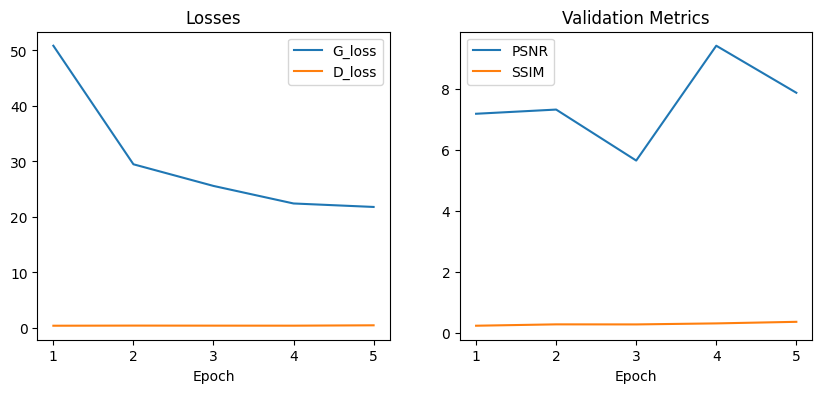

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(history["epoch"], history["G_loss"], label="G_loss")
plt.plot(history["epoch"], history["D_loss"], label="D_loss")
plt.xlabel("Epoch")
plt.legend()
plt.title("Training Losses")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history["epoch"], history["val_psnr"], label="Val PSNR (dB)")
plt.xlabel("Epoch")
plt.legend()
plt.title("Validation PSNR")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history["epoch"], history["val_ssim"], label="Val SSIM")
plt.xlabel("Epoch")
plt.legend()
plt.ylim(0.0, 1.0)
plt.title("Validation SSIM")
plt.show()

<font size=7 color="#5499C7">Metrics</font>

We report PSNR (dB) and SSIM for validation and test sets.


<font size=6 color="#5499C7">SSIM Definition</font>
<font size=5>

SSIM follows the standard definition from Wang et al. (2004) 

$$SSIM(x, y) = ((2μxμy + C1)(2σxy + C2)) / ((μx^2 + μy^2 + C1)(σx^2 + σy^2 + C2))$$

computed per-channel and averaged.

</font>


In [9]:
val_metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)
test_metrics = evaluate_model(test_loader, generator, max_batches=EVAL_MAX_BATCHES)

baseline_val = evaluate_model(val_loader, generator, max_batches=BASELINE_EVAL_MAX_BATCHES, baseline=True)
baseline_test = evaluate_model(test_loader, generator, max_batches=BASELINE_EVAL_MAX_BATCHES, baseline=True)

print("Validation metrics:", val_metrics)
print("Test metrics:", test_metrics)
print("Baseline (input-as-output) validation:", baseline_val)
print("Baseline (input-as-output) test:", baseline_test)

Validation metrics: {'psnr': 7.867834568023682, 'ssim': 0.3696812689304352}
Test metrics: {'psnr': 7.867834568023682, 'ssim': 0.3696812689304352}
Baseline (input-as-output) validation: {'psnr': 7.994063854217529, 'ssim': 0.6382015347480774}
Baseline (input-as-output) test: {'psnr': 7.994063854217529, 'ssim': 0.6382015347480774}


<font size=7 color="#5499C7">Visualization</font>

We visualize input, model output, and ground truth side by side.


<font size=6 color="#5499C7">Sample</font>
<font size=5>

The helper below renders a single sample and reports PSNR/SSIM for that sample.

</font>


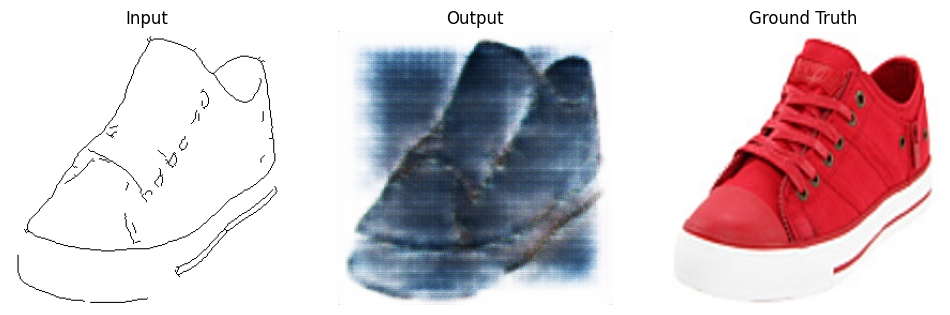

PSNR: 8.54 dB | SSIM: 0.3523


In [10]:
@torch.no_grad()
def show_sample(split="val", index=0, random_sample=False):
    ds_map = {"train": train_ds, "val": val_ds, "test": test_ds}
    ds = ds_map[split]
    if random_sample:
        index = random.randint(0, len(ds) - 1)

    real_A, real_B, mask = ds[index]
    real_A = real_A.unsqueeze(0).to(DEVICE)
    real_B = real_B.unsqueeze(0).to(DEVICE)
    mask = mask.unsqueeze(0).to(DEVICE)

    generator.eval()
    fake_B = generator(real_A)

    pred = denormalize(fake_B).cpu()
    target = denormalize(real_B).cpu()
    input_img = denormalize(real_A).cpu()

    sample_psnr = psnr(pred, target)[0].item()
    sample_ssim = ssim(pred, target)[0].item()

    if CORRUPT_INPUT:
        masked_mse_val = masked_mse(pred, target, mask.cpu())
        masked_psnr = 10 * torch.log10((1.0 ** 2) / (masked_mse_val + 1e-8))
        masked_psnr = masked_psnr[0].item()
        masked_ssim = ssim(pred * mask.cpu(), target * mask.cpu())[0].item()
    else:
        masked_psnr = None
        masked_ssim = None

    _, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax in axes:
        ax.axis("off")

    axes[0].imshow(np.transpose(input_img[0].numpy(), (1, 2, 0)))
    axes[0].set_title("Input")
    axes[1].imshow(np.transpose(pred[0].numpy(), (1, 2, 0)))
    axes[1].set_title("Output")
    axes[2].imshow(np.transpose(target[0].numpy(), (1, 2, 0)))
    axes[2].set_title("Ground Truth")
    plt.show()

    print(f"PSNR: {sample_psnr:.2f} dB | SSIM: {sample_ssim:.4f}")
    if CORRUPT_INPUT:
        print(f"Masked PSNR: {masked_psnr:.2f} dB | Masked SSIM: {masked_ssim:.4f}")

show_sample(split="val", index=0, random_sample=True)

<font size=7 color="#5499C7">Interactive Demo</font>

The UI lets a grader select a split and sample index, view results, and compute PSNR/SSIM.


<font size=6 color="#5499C7">Usage</font>
<font size=5>

If ipywidgets is available, use the interactive controls below. Otherwise, call show_sample(...) directly for a manual demo.

</font>


In [11]:
def build_ui():
    try:
        import ipywidgets as widgets
        from IPython.display import display, clear_output
    except Exception:
        print("ipywidgets is not available. Use show_sample(split=..., index=..., random_sample=...).")
        return

    split_widget = widgets.Dropdown(options=["train", "val", "test"], value="val", description="Split")
    index_widget = widgets.IntSlider(min=0, max=max(len(val_ds) - 1, 0), step=1, value=0, description="Index")
    random_button = widgets.Button(description="Random Sample")
    eval_button = widgets.Button(description="Eval Small Batch")
    output = widgets.Output()

    def update_index_range(*_):
        ds_map = {"train": train_ds, "val": val_ds, "test": test_ds}
        max_idx = max(len(ds_map[split_widget.value]) - 1, 0)
        index_widget.max = max_idx
        if index_widget.value > max_idx:
            index_widget.value = max_idx

    def render_sample(*_):
        with output:
            clear_output(wait=True)
            show_sample(split=split_widget.value, index=index_widget.value, random_sample=False)

    def on_random(_):
        ds_map = {"train": train_ds, "val": val_ds, "test": test_ds}
        ds = ds_map[split_widget.value]
        if len(ds) > 0:
            index_widget.value = random.randint(0, len(ds) - 1)

    def on_eval(_):
        with output:
            clear_output(wait=True)
            metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)
            print("Quick validation metrics:", metrics)
            render_sample()

    split_widget.observe(update_index_range, names="value")
    index_widget.observe(render_sample, names="value")
    random_button.on_click(on_random)
    eval_button.on_click(on_eval)

    display(widgets.HBox([split_widget, index_widget, random_button, eval_button]))
    display(output)
    render_sample()

build_ui()

Output()